# *HW1 - ECG Arrhythmia Analysis*

# *1. Data Acquisition*

In [1]:
# # Download the file into memory
# import requests, zipfile, io

# url = "https://physionet.org/static/published-projects/mitdb/mit-bih-arrhythmia-database-1.0.0.zip"
# r = requests.get(url)
# z = zipfile.ZipFile(io.BytesIO(r.content))
# z.extractall("mitdb")  
# print("Download and extraction complete!")

In [2]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, iirnotch, spectrogram

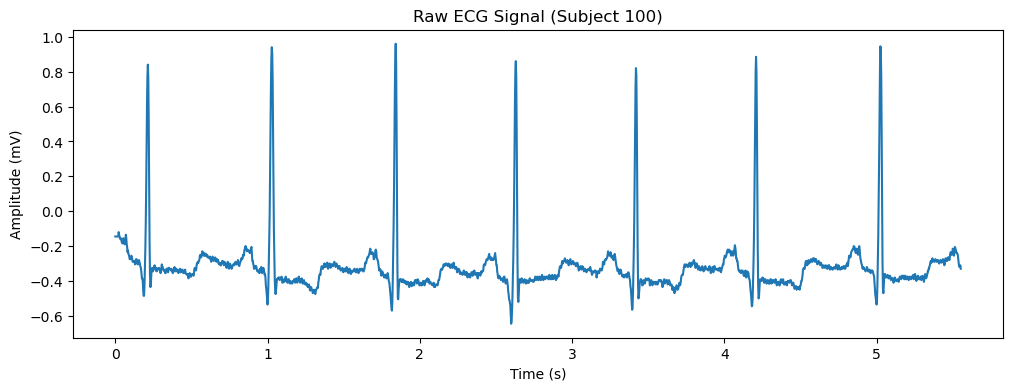

In [3]:
# Download and read record 100
record = wfdb.rdrecord('100', pn_dir='mitdb')  
annotation = wfdb.rdann('100', 'atr', pn_dir='mitdb')

# Extract signal
signal = record.p_signal[:,0]   # channel 0 (ECG lead)
fs = record.fs                 # sampling frequency
t = np.arange(len(signal)) / fs
plt.figure(figsize=(12,4))
plt.plot(t[:2000], signal[:2000])
plt.title("Raw ECG Signal (Subject 100)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.show()


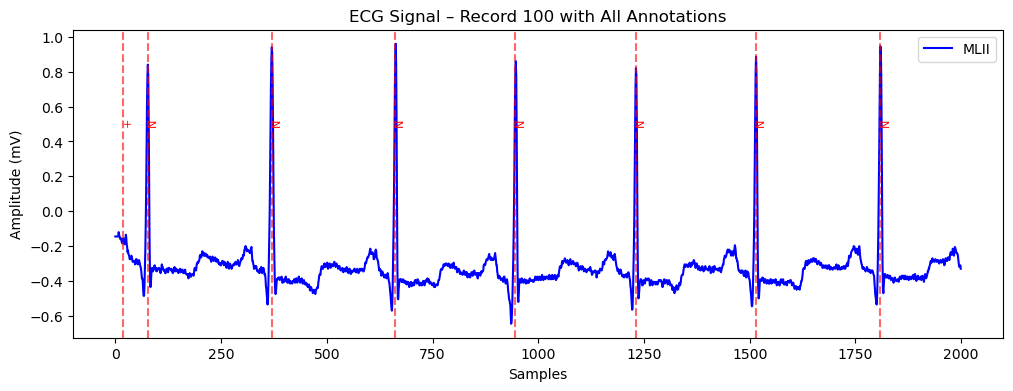

In [4]:
# Plot with annotations
record = wfdb.rdrecord('100', pn_dir='mitdb')
annotation = wfdb.rdann('100', 'atr', pn_dir='mitdb')

# Plot ECG (first 2000 samples for clarity)
plt.figure(figsize=(12,4))
plt.plot(record.p_signal[:2000,0], label=record.sig_name[0], color='blue')
plt.title("ECG Signal – Record 100 with All Annotations")
plt.xlabel("Samples")
plt.ylabel("Amplitude (mV)")

# Mark all annotated beats
for s, sym in zip(annotation.sample, annotation.symbol):
    if s < 2000:  # only within first 2000 samples
        plt.axvline(x=s, color='red', linestyle='--', alpha=0.6)
        plt.text(s, 0.5, sym, rotation=90, fontsize=8, color='red')

plt.legend()
plt.show()



Selected records: ['222', '107', '101', '118', '116', '115', '108', '106', '214', '105']


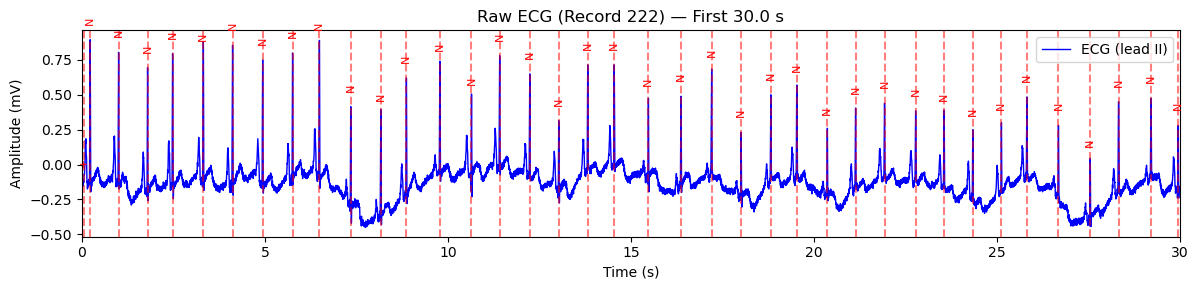

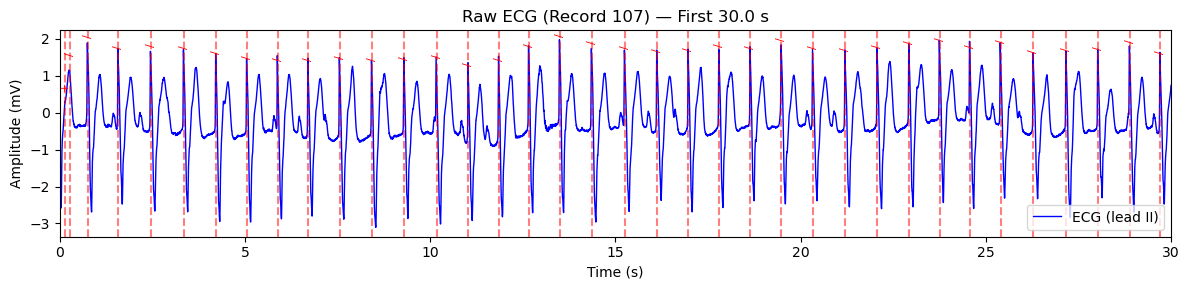

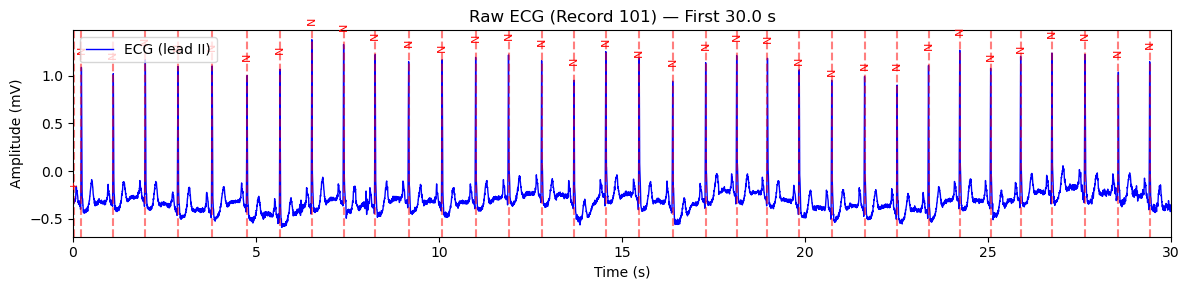

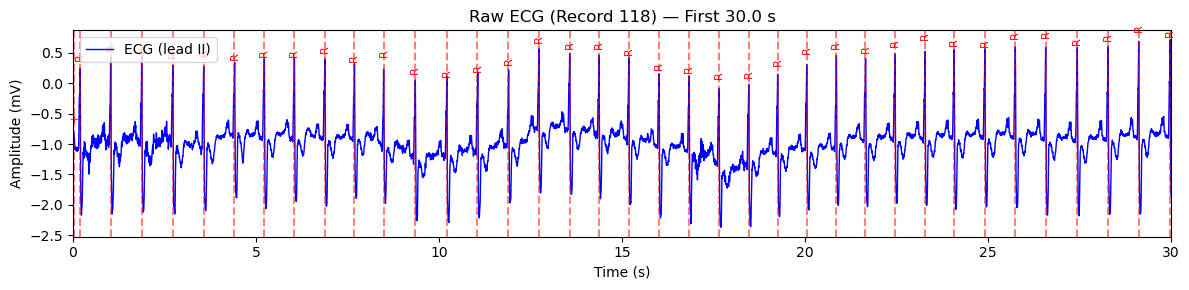

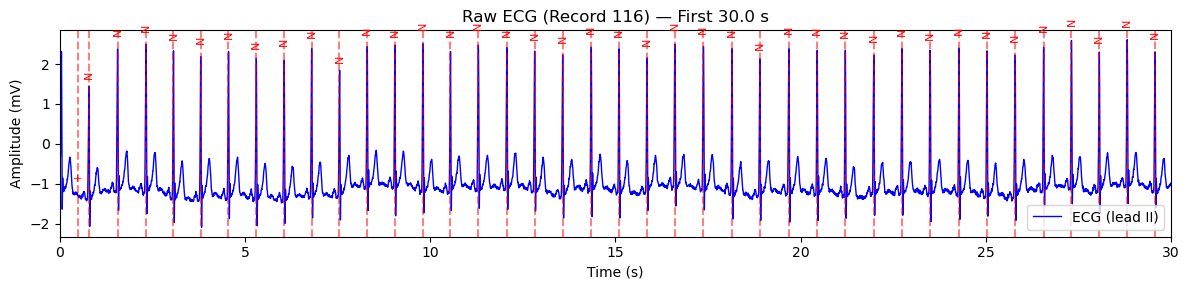

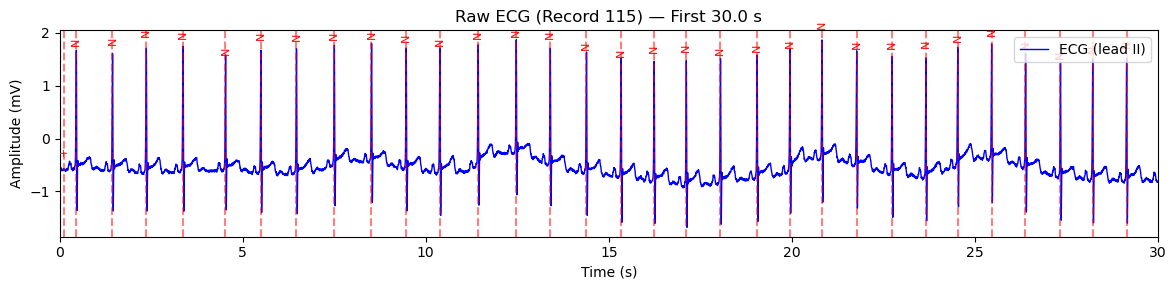

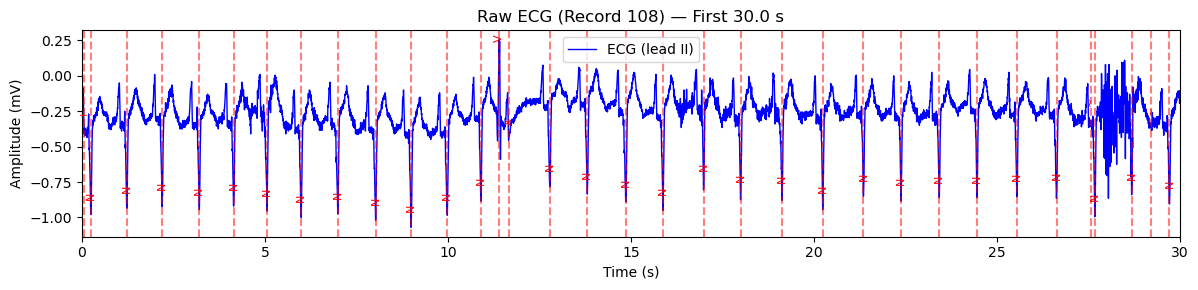

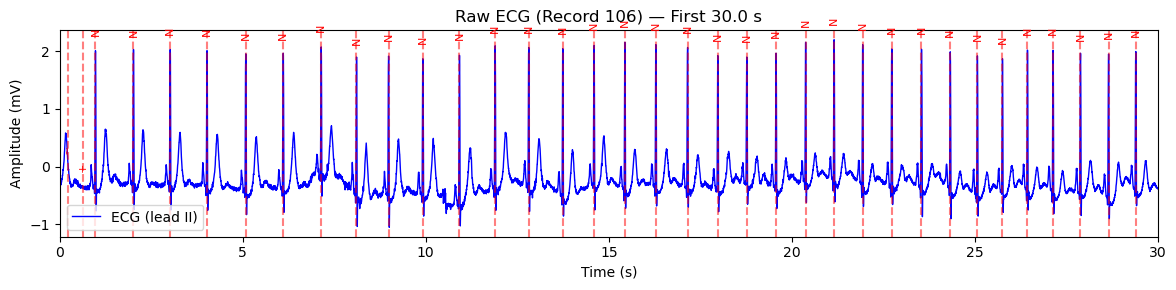

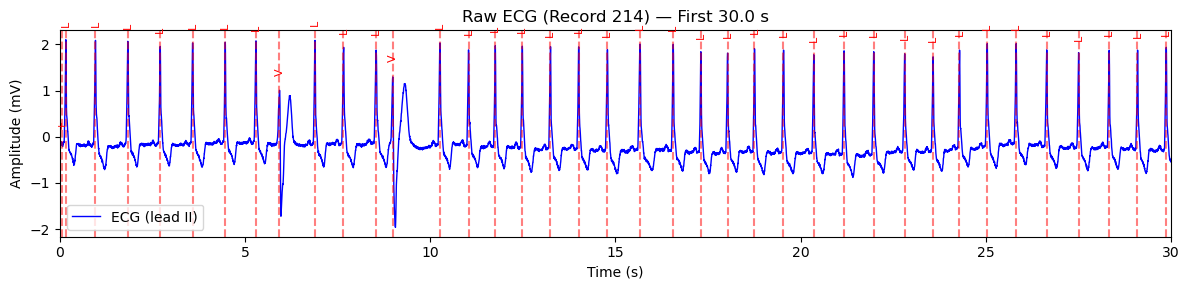

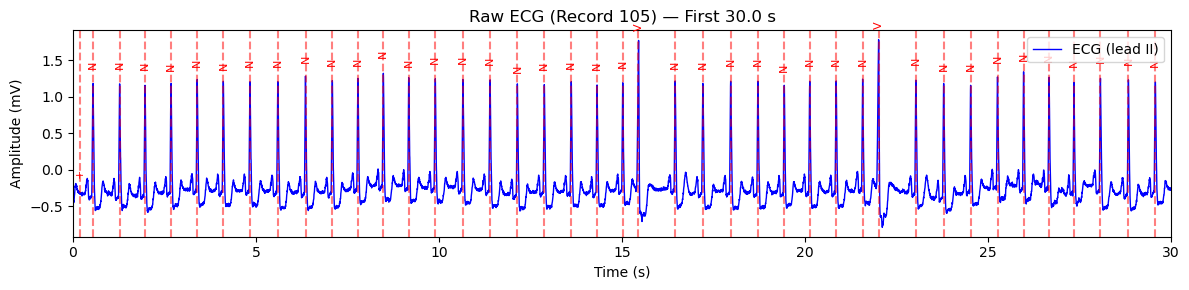

In [5]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt
import random

# Full MIT-BIH record list
all_records = [
    '100','101','102','103','104','105','106','107','108','109',
    '111','112','113','114','115','116','117','118','119','121',
    '122','123','124','200','201','202','203','205','207','208',
    '209','210','212','213','214','215','217','219','220','221',
    '222','223','228','230','231','232','233','234'
]

# Randomly select 10 records
random.seed(42)
records_10 = random.sample(all_records, 10)
print("Selected records:", records_10)

# Plotting parameters
plot_seconds = 30.0  # first 30 seconds

for rec_id in records_10:
    # Load record and annotation
    record = wfdb.rdrecord(rec_id, pn_dir='mitdb')
    annotation = wfdb.rdann(rec_id, 'atr', pn_dir='mitdb')
    signal = record.p_signal[:,0]  # Lead II
    fs = record.fs
    
    # Determine samples to plot
    end_sample = int(plot_seconds * fs)
    t = np.arange(end_sample) / fs  # time in seconds
    
    # Plot ECG with annotations
    plt.figure(figsize=(12,3))
    plt.plot(t, signal[:end_sample], lw=1, label='ECG (lead II)', color='blue')
    
    # Mask annotations inside window
    mask = (annotation.sample < end_sample)
    ann_samples = annotation.sample[mask]
    ann_symbols = np.array(annotation.symbol)[mask]
    
    # Offset for annotation text
    ymin, ymax = np.min(signal[:end_sample]), np.max(signal[:end_sample])
    y_off = (ymax - ymin) * 0.08
    
    for s, sym in zip(ann_samples, ann_symbols):
        sec = s / fs
        plt.axvline(x=sec, color='red', linestyle='--', alpha=0.5)
        plt.text(sec, signal[s] + y_off, sym, color='red', fontsize=8, rotation=90,
                 va='bottom', ha='center')
    
    plt.title(f"Raw ECG (Record {rec_id}) — First {plot_seconds:.1f} s")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude (mV)")
    plt.xlim(0, plot_seconds)
    plt.legend()
    plt.tight_layout()
    plt.show()


# *2. Preprocessing*

## Preprocessing Rationale

ECG signals often contain unwanted noise, such as slow baseline drift caused by breathing or body movement, and high-frequency noise from muscle activity or electronic interference. Preprocessing is essential to **clean the signal**, making it easier to analyze and ensuring accurate detection of cardiac features like R-peaks.

To address this, we applied three types of filters:

- **High-pass (0.5 Hz):** Removes slow baseline drift and low-frequency artifacts, centering the signal around zero. This helps prevent false detections caused by slow fluctuations.  
- **Low-pass (40 Hz):** Eliminates high-frequency noise, such as electromyographic (EMG) activity or power-line interference, resulting in a smoother ECG waveform.  
- **Band-pass (0.5–40 Hz):** Combines the effects of high-pass and low-pass filtering, preserving the essential ECG components (P, QRS, T waves) while removing both low- and high-frequency noise.  

We chose a **4th-order Butterworth filter** because of its **smooth frequency response** and minimal ripple in the passband. To avoid phase distortion of the QRS complexes, we applied **zero-phase filtering using `filtfilt`**, which filters the signal forward and backward.  

Among the three filters, the **band-pass filter** provided the **cleanest and most reliable signal**, making it ideal for downstream tasks like **R-peak detection, heart rate calculation, and HRV analysis**. This step ensures that the extracted features reflect true cardiac activity rather than noise or artifacts.
raction.


In [6]:
from scipy.signal import butter, filtfilt, freqz, welch
plt.rcParams["figure.dpi"] = 110

# load record 100 (comment out if you've already loaded it)
record = wfdb.rdrecord('100', pn_dir='mitdb')
annotation = wfdb.rdann('100', 'atr', pn_dir='mitdb')

# pick lead 0 / variable names
ecg = record.p_signal[:,0]
fs = float(record.fs)
n = len(ecg)
print(f"Record {record.record_name}: {n} samples, fs = {fs} Hz")


Record 100: 650000 samples, fs = 360.0 Hz


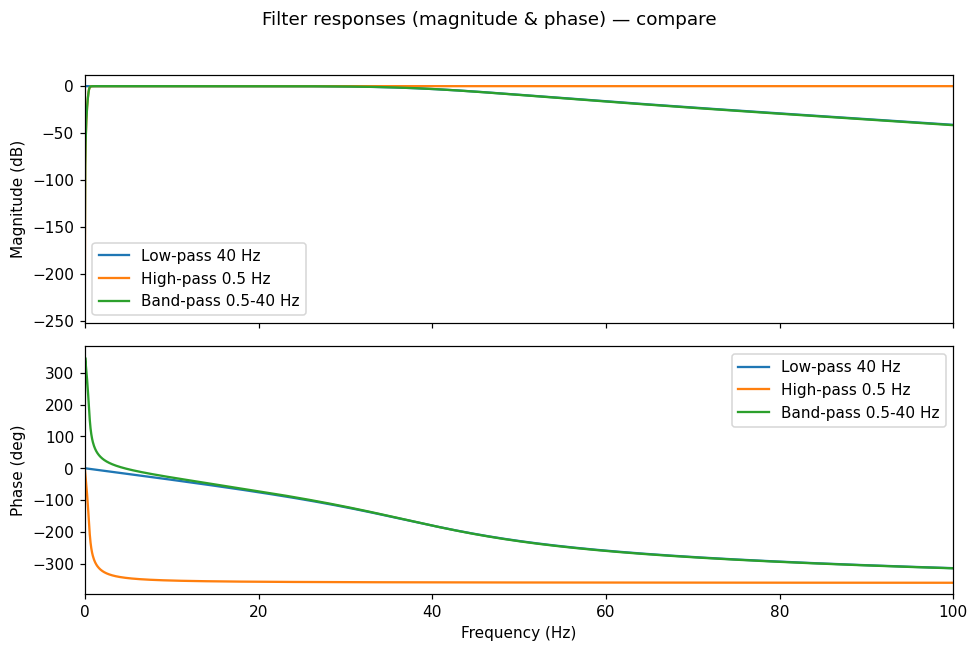

In [7]:
# Butterworth filters (order 4) and show their magnitude & phase responses
def design_butter(cutoff, fs, btype='low', order=4):
    nyq = 0.5 * fs
    if isinstance(cutoff, (list, tuple, np.ndarray)):
        wn = [c/nyq for c in cutoff]
    else:
        wn = cutoff/nyq
    b, a = butter(order, wn, btype=btype, analog=False)
    return b, a

# filter configurations (you can change cutoff/order to try alternatives)
b_lp, a_lp   = design_butter(40.0, fs, btype='low',  order=4)  # Low-pass 40 Hz
b_hp, a_hp   = design_butter(0.5,  fs, btype='high', order=4)  # High-pass 0.5 Hz
b_bp, a_bp   = design_butter([0.5, 40.0], fs, btype='band', order=4)  # Band-pass 0.5-40 Hz

# freq response helper
def plot_response(b, a, fs, label, ax_mag=None, ax_phase=None, worN=4096):
    w, h = freqz(b, a, worN=worN)
    freqs = w * fs / (2*np.pi)
    mag_db = 20*np.log10(np.abs(h) + 1e-12)
    phase_deg = np.unwrap(np.angle(h)) * (180/np.pi)
    if ax_mag is None:
        plt.figure(figsize=(10,4))
        plt.subplot(1,2,1)
        plt.plot(freqs, mag_db)
        plt.xlim(0, 100)
        plt.title(f"{label} — Magnitude (dB)")
        plt.xlabel("Frequency (Hz)"); plt.ylabel("Magnitude (dB)")
        plt.subplot(1,2,2)
        plt.plot(freqs, phase_deg)
        plt.xlim(0,100)
        plt.title(f"{label} — Phase (deg)")
        plt.xlabel("Frequency (Hz)"); plt.ylabel("Phase (deg)")
        plt.tight_layout()
    else:
        ax_mag.plot(freqs, mag_db, label=label)
        ax_phase.plot(freqs, phase_deg, label=label)

# combined figure for easy comparison
fig, (axm, axp) = plt.subplots(2,1, figsize=(9,6), sharex=True)
plot_response(b_lp, a_lp, fs, 'Low-pass 40 Hz', ax_mag=axm, ax_phase=axp)
plot_response(b_hp, a_hp, fs, 'High-pass 0.5 Hz', ax_mag=axm, ax_phase=axp)
plot_response(b_bp, a_bp, fs, 'Band-pass 0.5-40 Hz', ax_mag=axm, ax_phase=axp)
axm.set_xlim(0,100); axm.set_ylabel('Magnitude (dB)'); axp.set_ylabel('Phase (deg)')
axm.legend(); axp.legend()
axp.set_xlabel('Frequency (Hz)')
plt.suptitle("Filter responses (magnitude & phase) — compare")
plt.tight_layout(rect=[0,0,1,0.96])
plt.show()


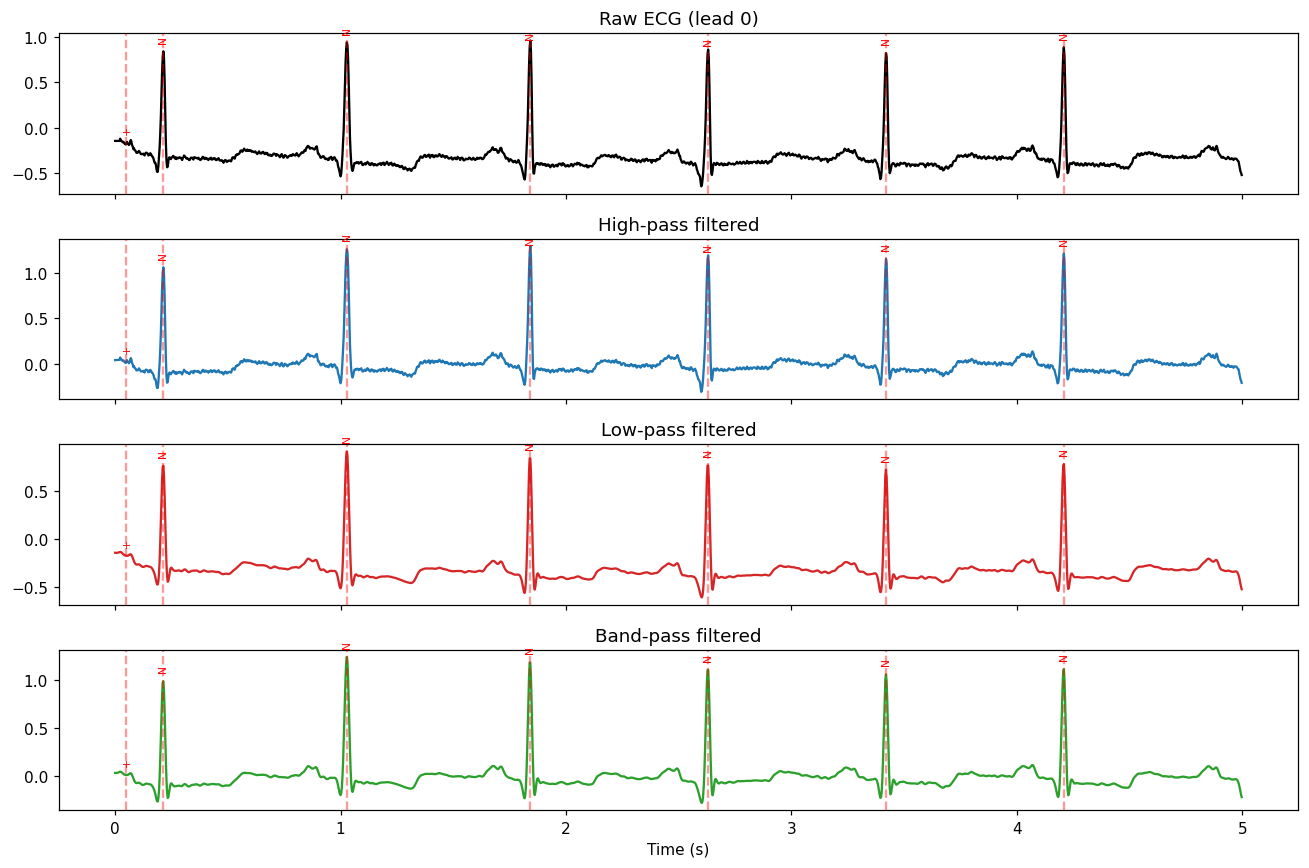

In [8]:
# Cell 3 — apply zero-phase filtering (filtfilt) and show raw vs filtered with annotations
ecg_lp = filtfilt(b_lp, a_lp, ecg)
ecg_hp = filtfilt(b_hp, a_hp, ecg)
ecg_bp = filtfilt(b_bp, a_bp, ecg)

# small function to plot a window in seconds with annotation symbols
def plot_window_with_annotations(start_s=0.0, duration_s=5.0):
    start = int(start_s * fs)
    end   = int((start_s + duration_s) * fs)
    t = np.arange(start, end)/fs
    window_raw = ecg[start:end]
    window_lp  = ecg_lp[start:end]
    window_hp  = ecg_hp[start:end]
    window_bp  = ecg_bp[start:end]

    fig, axes = plt.subplots(4,1, figsize=(12,8), sharex=True)
    axes[0].plot(t, window_raw, color='k', label='Raw')
    axes[0].set_title('Raw ECG (lead 0)')
    axes[1].plot(t, window_hp, color='tab:blue', label='High-pass (0.5 Hz)')
    axes[1].set_title('High-pass filtered')
    axes[2].plot(t, window_lp, color='tab:red', label='Low-pass (40 Hz)')
    axes[2].set_title('Low-pass filtered')
    axes[3].plot(t, window_bp, color='tab:green', label='Band-pass (0.5–40 Hz)')
    axes[3].set_title('Band-pass filtered')
    axes[3].set_xlabel('Time (s)')

    # annotations (symbols) for those inside the window
    ann_mask = (annotation.sample >= start) & (annotation.sample < end)
    ann_samples_win = annotation.sample[ann_mask]
    ann_symbols_win = np.array(annotation.symbol)[ann_mask]
    for ax in axes:
        for s, sym in zip(ann_samples_win, ann_symbols_win):
            sec = s / fs
            ax.axvline(sec, color='red', linestyle='--', alpha=0.4)
            # place text a bit above the current signal's value at that sample (if inside range)
            # choose y position using the particular axis's data array
            # we map s->index in the axis's displayed array: idx = s - start
            idx = int(s - start)
            if 0 <= idx < (end-start):
                # choose a small offset relative to axis range:
                y = [window_raw[idx], window_hp[idx], window_lp[idx], window_bp[idx]][axes.tolist().index(ax)]
                offs = 0.06*(np.max(window_raw) - np.min(window_raw))
                ax.text(sec, y+offs, sym, color='red', fontsize=7, rotation=90, va='bottom', ha='center')

    plt.tight_layout()
    plt.show()

# Example: plot first 5 seconds
plot_window_with_annotations(start_s=0.0, duration_s=5.0)


# *3. Signal Transformations*

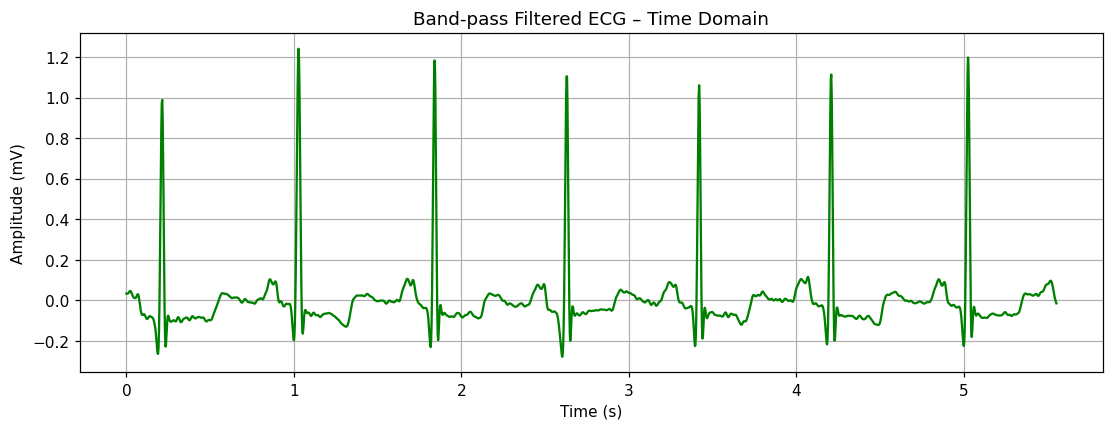

In [9]:
# Time-domain plot (first 5 seconds)
t = np.arange(len(ecg_bp)) / fs  # time axis in seconds
plt.figure(figsize=(12,4))
plt.plot(t[:2000], ecg_bp[:2000], color='green')
plt.title("Band-pass Filtered ECG – Time Domain")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.grid(True)
plt.show()


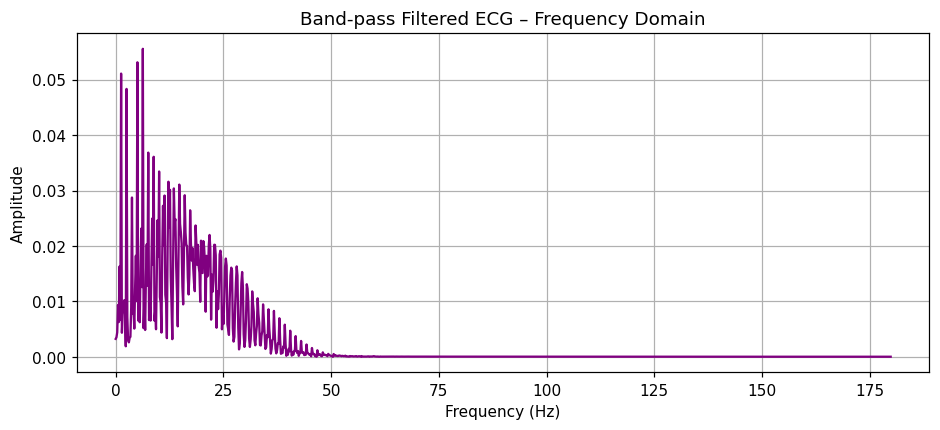

In [10]:
from scipy.fft import fft, fftfreq

# FFT
N = 2000  # number of samples to plot
yf = fft(ecg_bp[:N])
xf = fftfreq(N, 1/fs)

plt.figure(figsize=(10,4))
plt.plot(xf[:N//2], 2.0/N * np.abs(yf[:N//2]), color='purple')
plt.title("Band-pass Filtered ECG – Frequency Domain")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()


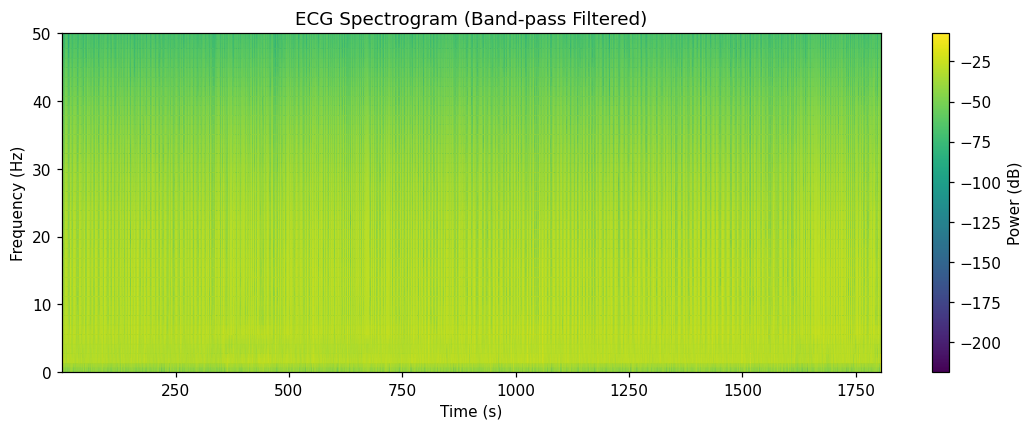

In [11]:
from scipy.signal import spectrogram

f, t_spec, Sxx = spectrogram(ecg_bp, fs=fs, nperseg=256, noverlap=128)
plt.figure(figsize=(12,4))
plt.pcolormesh(t_spec, f, 10*np.log10(Sxx), shading='gouraud')
plt.title("ECG Spectrogram (Band-pass Filtered)")
plt.ylabel("Frequency (Hz)")
plt.xlabel("Time (s)")
plt.colorbar(label="Power (dB)")
plt.ylim(0,50)  # focus on ECG-relevant frequencies
plt.show()


## 10 records comparision

In [12]:
import random

# List of commonly used MIT-BIH records
all_records = [
    '100','101','102','103','104','105','106','107','108','109',
    '111','112','113','114','115','116','117','118','119','121',
    '122','123','124','200','201','202','203','205','207','208',
    '209','210','212','213','214','215','217','219','220','221',
    '222','223','228','230','231','232','233','234'
]


# Randomly choose 10 records
random.seed(42)
records_10 = random.sample(all_records, 10)
print("Selected records:", records_10)


Selected records: ['222', '107', '101', '118', '116', '115', '108', '106', '214', '105']


In [13]:
from scipy.signal import butter, filtfilt

def bandpass_filter(signal, fs, lowcut=0.5, highcut=40, order=4):
    b, a = butter(order, [lowcut/(fs/2), highcut/(fs/2)], btype='band')
    filtered = filtfilt(b, a, signal)
    return filtered


In [14]:
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq
from scipy.signal import spectrogram
import numpy as np

def plot_time_domain(sig, fs, record_id, samples=10000):
    t = np.arange(len(sig)) / fs
    plt.figure(figsize=(12,3))
    plt.plot(t[:samples], sig[:samples], color='blue')
    plt.title(f"Record {record_id} – Time Domain")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude (mV)")
    plt.grid(True)
    plt.show()

def plot_frequency_domain(sig, fs, record_id, samples=10000):
    N = samples
    yf = fft(sig[:N])
    xf = fftfreq(N, 1/fs)
    plt.figure(figsize=(12,3))
    plt.plot(xf[:N//2], 2.0/N * np.abs(yf[:N//2]), color='red')
    plt.title(f"Record {record_id} – Frequency Domain")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.show()

def plot_spectrogram(sig, fs, record_id, nperseg=128, noverlap=64):
    f, t_spec, Sxx = spectrogram(sig, fs=fs, nperseg=nperseg, noverlap=noverlap)
    plt.figure(figsize=(12,3))
    plt.pcolormesh(t_spec, f, 10*np.log10(Sxx), shading='gouraud', cmap='plasma')  # yellow–purple
    plt.title(f"Record {record_id} – Spectrogram")
    plt.xlabel("Time (s)")
    plt.ylabel("Frequency (Hz)")
    plt.colorbar(label="Power (dB)")
    plt.ylim(0,50)
    plt.show()


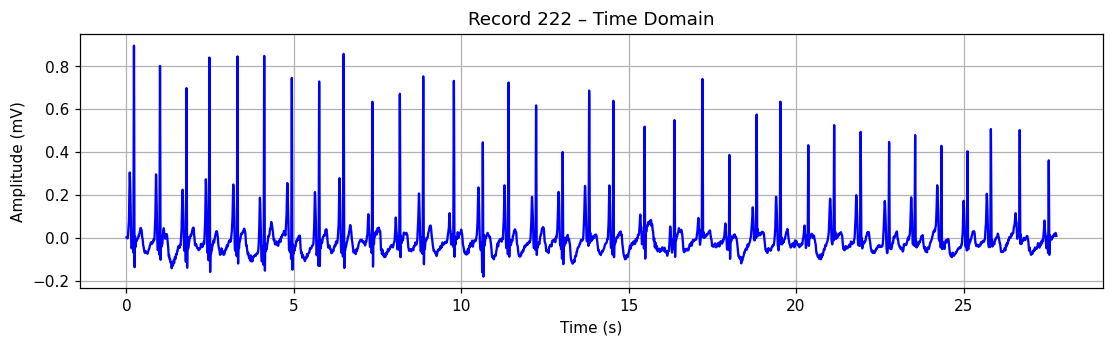

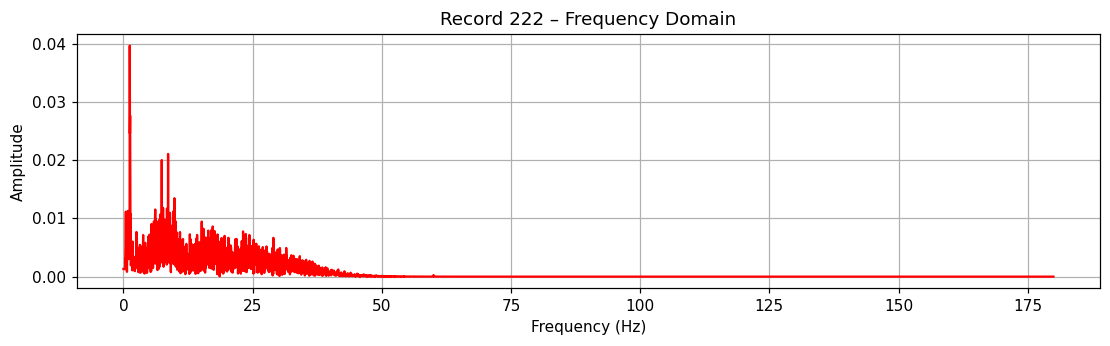

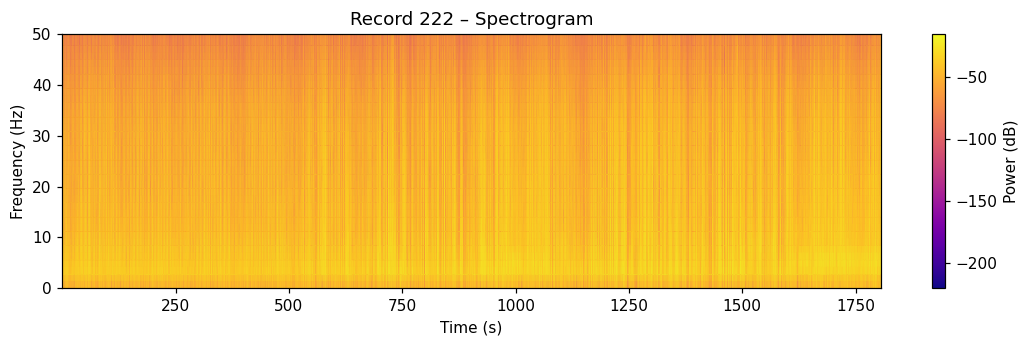

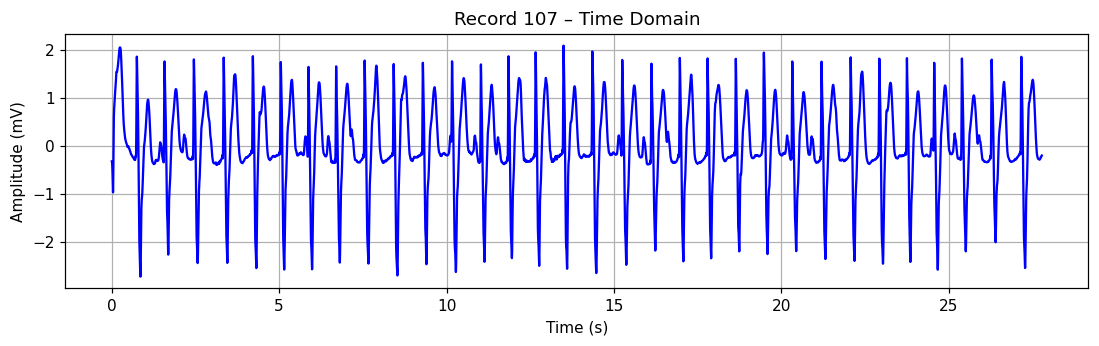

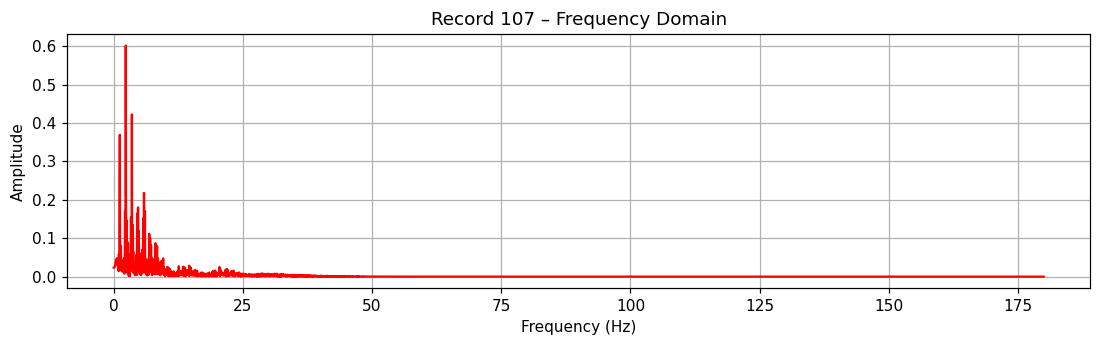

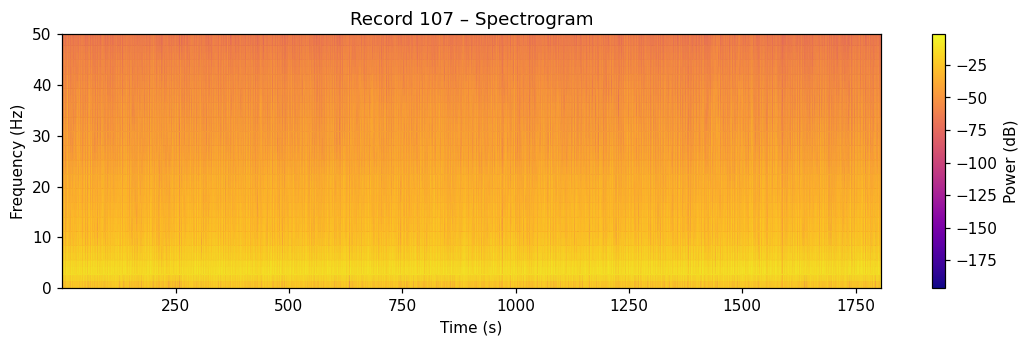

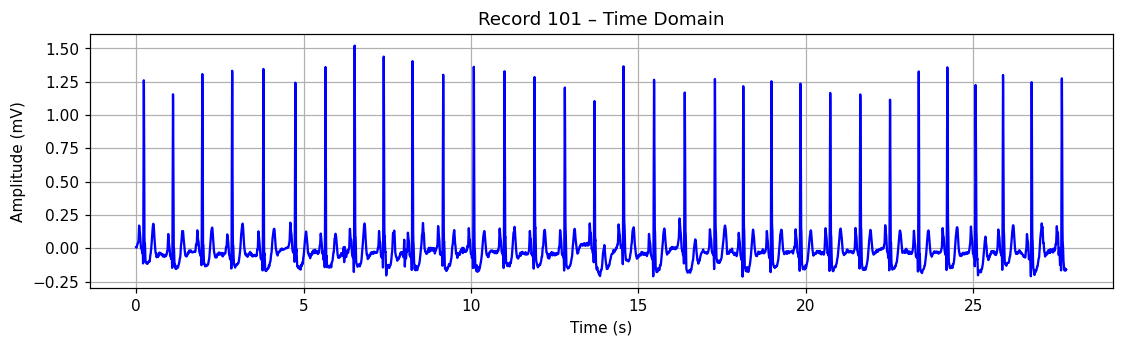

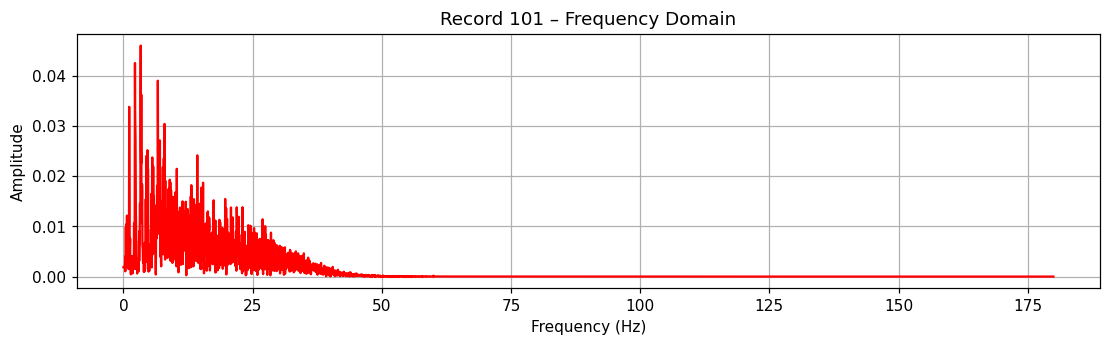

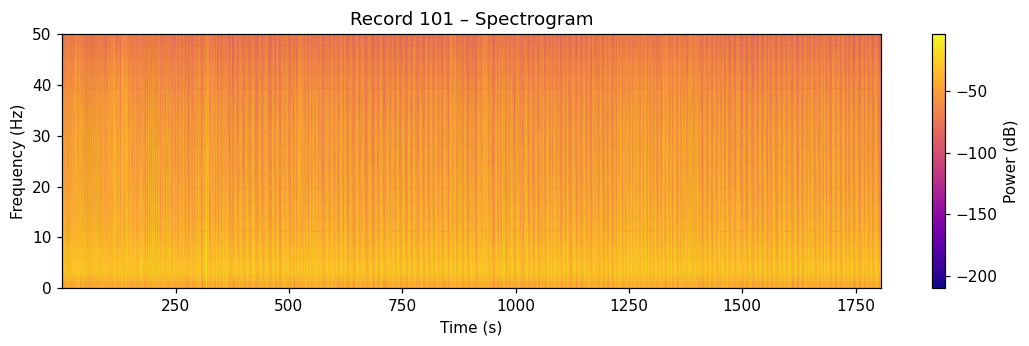

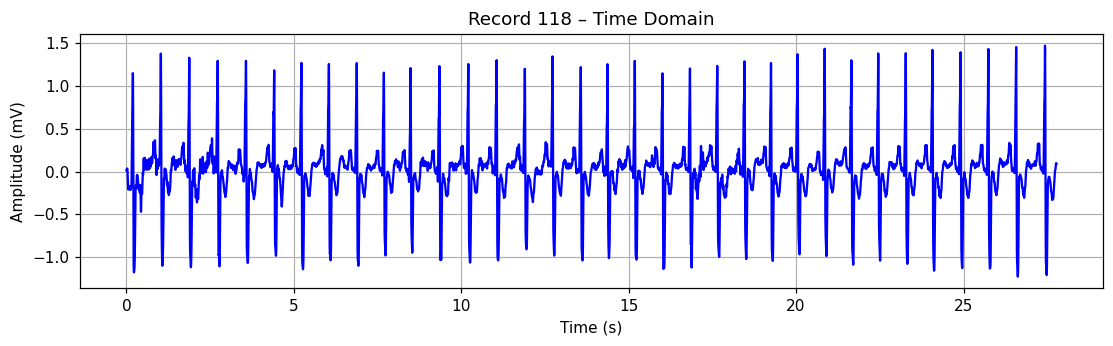

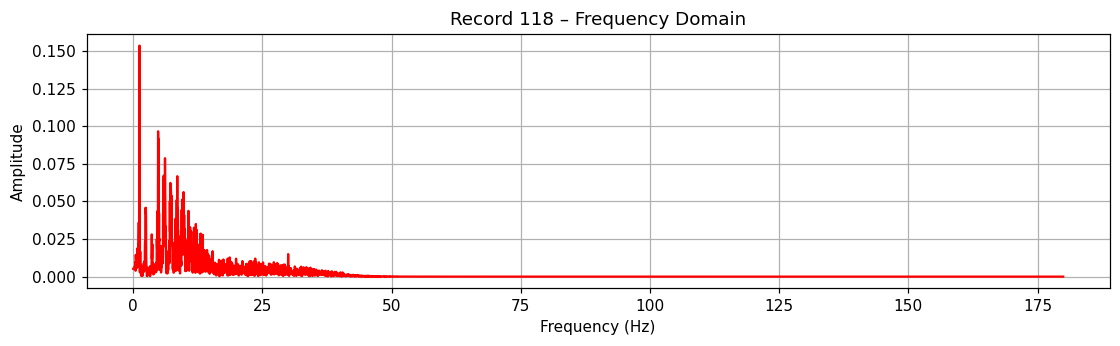

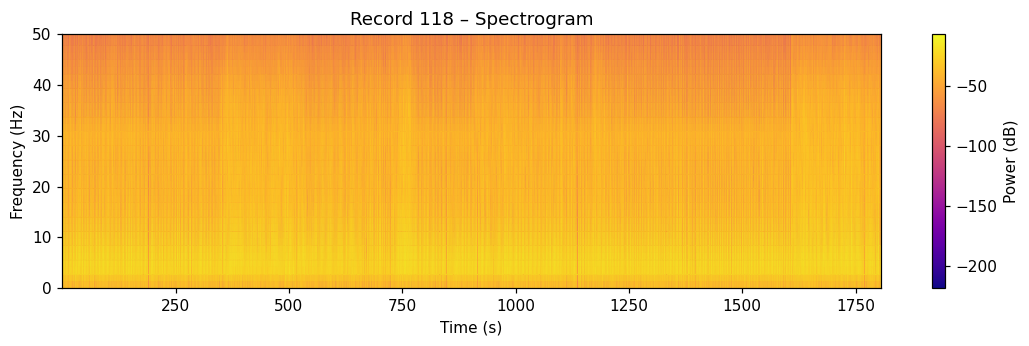

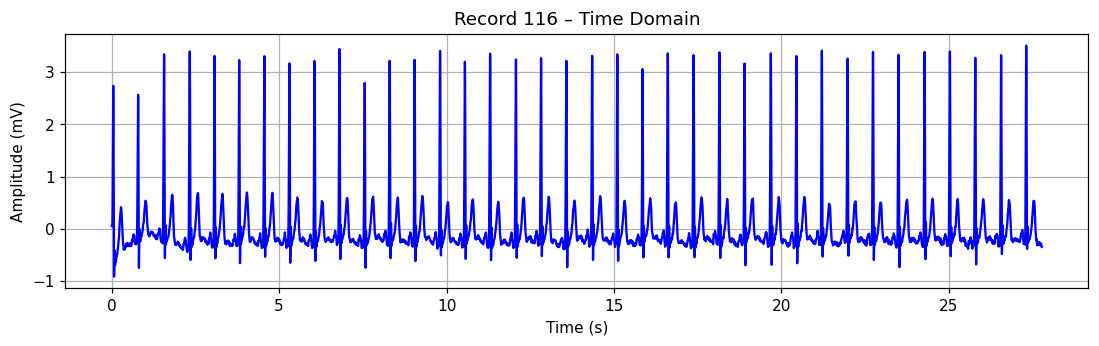

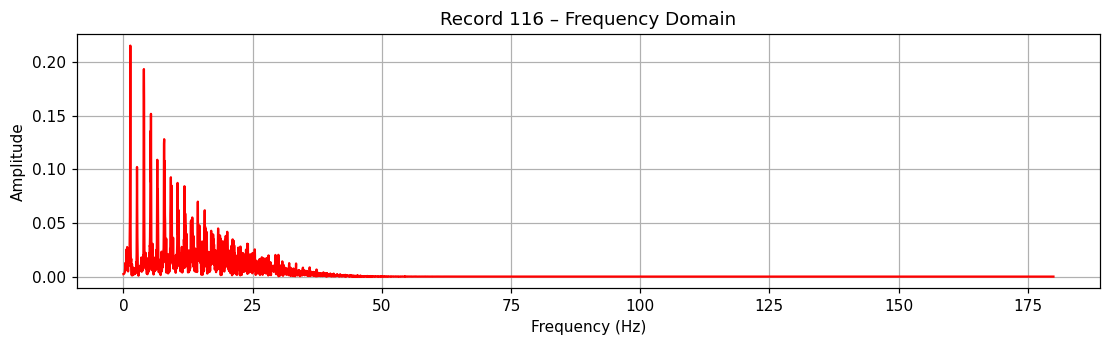

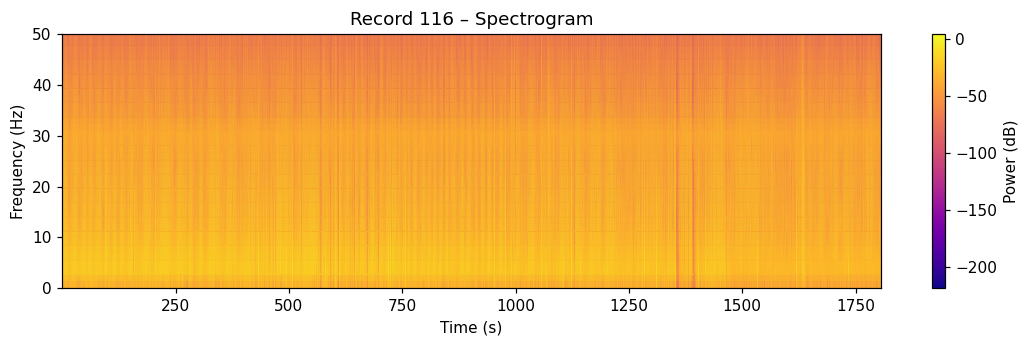

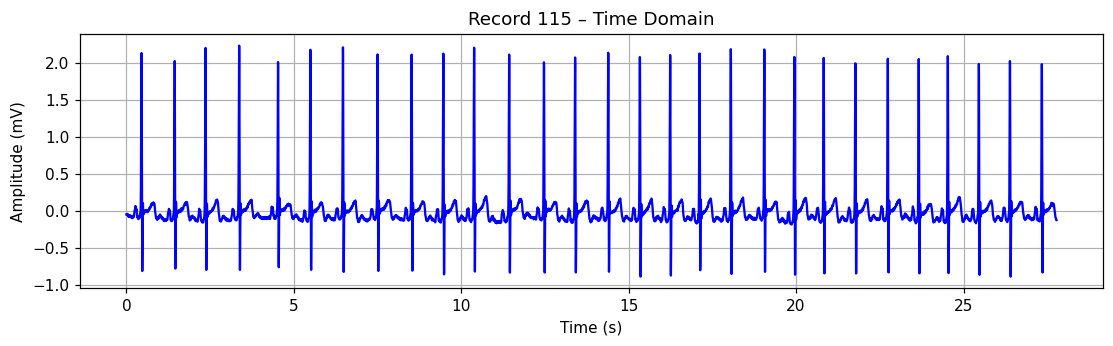

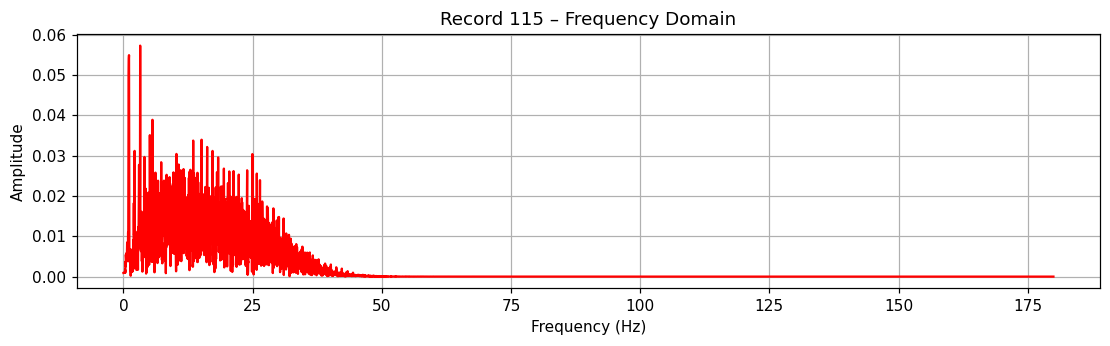

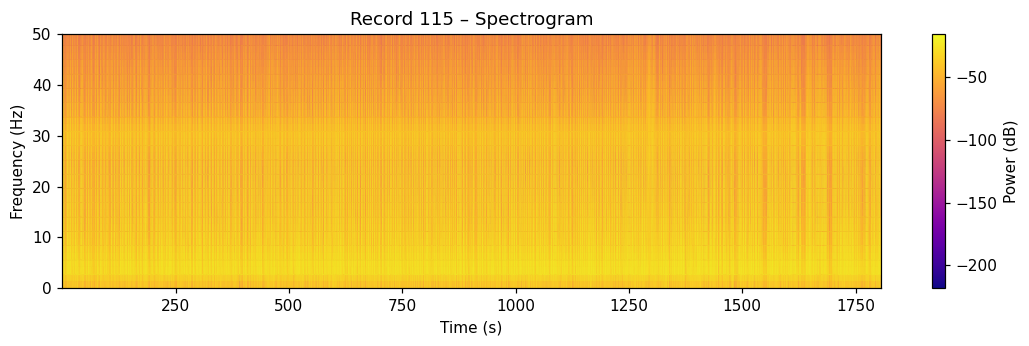

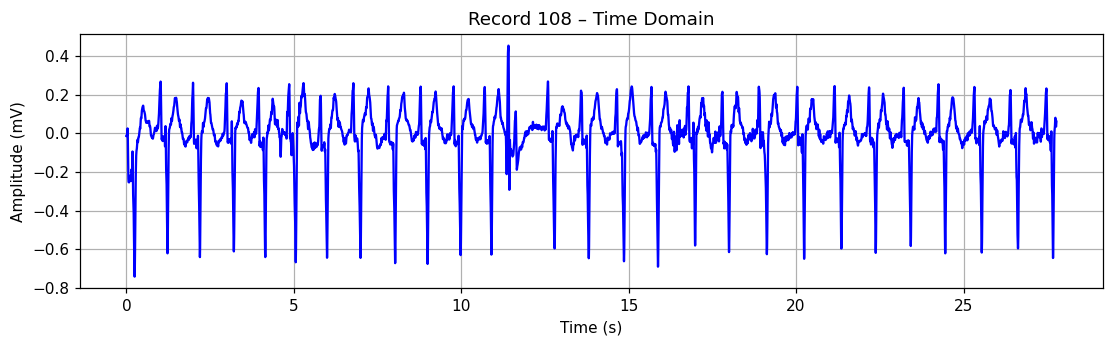

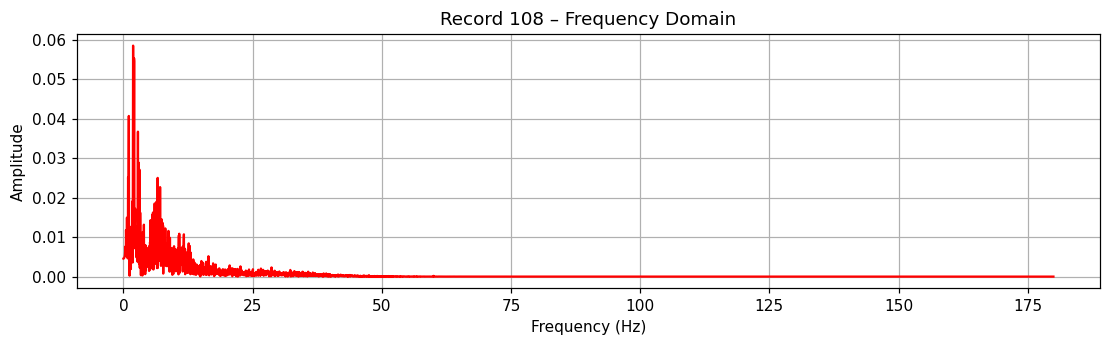

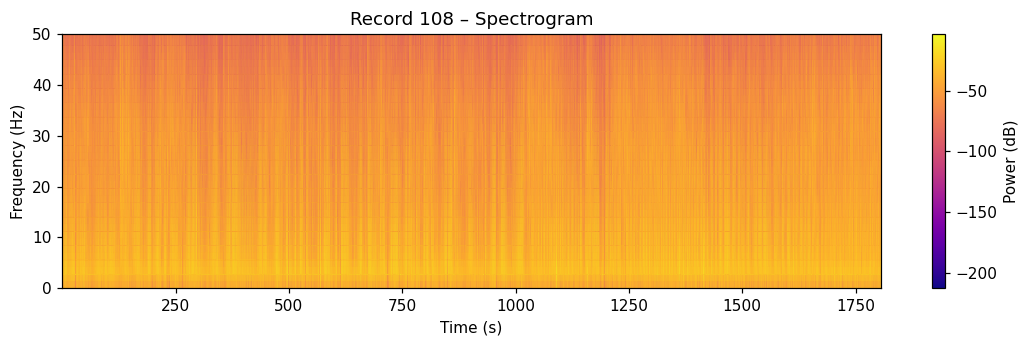

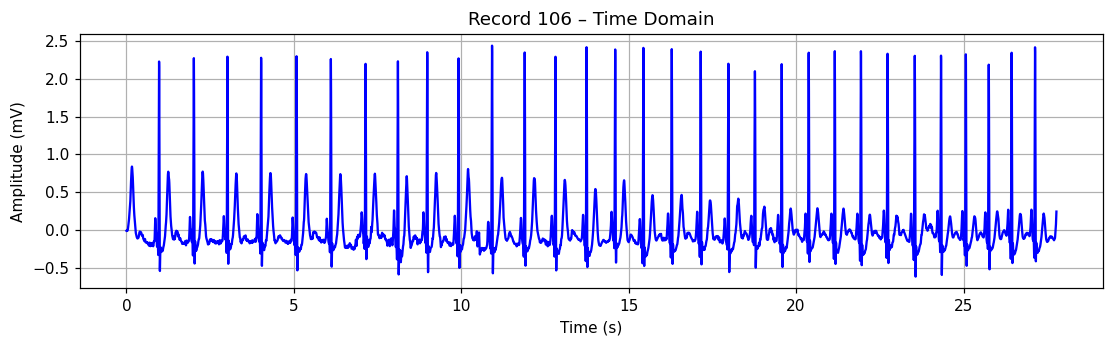

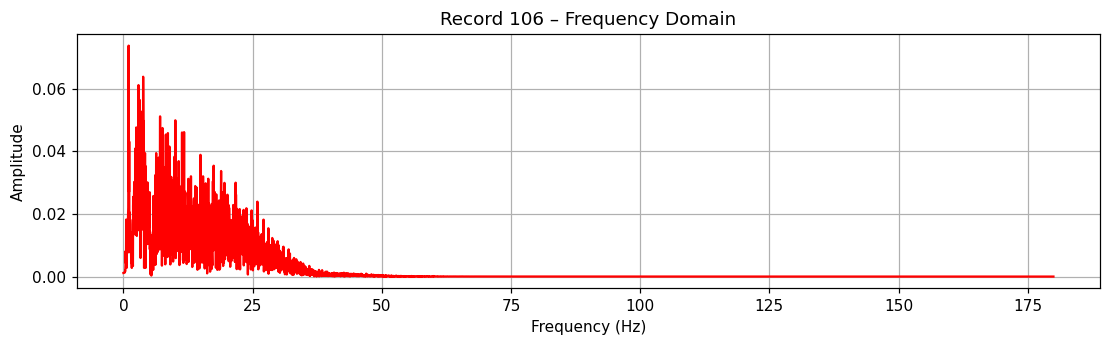

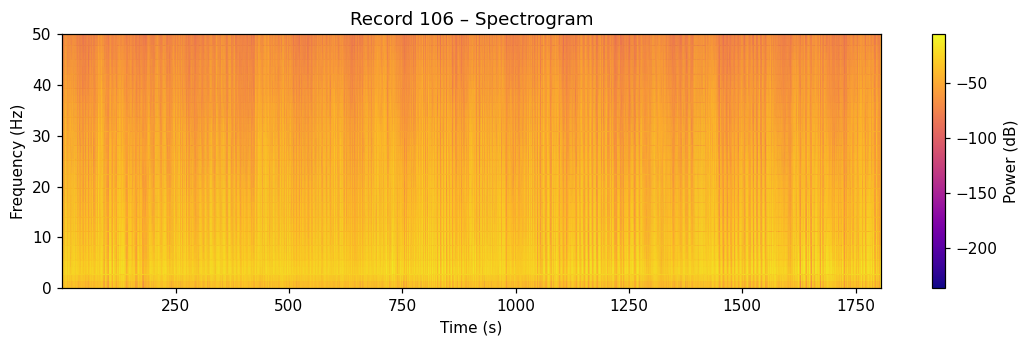

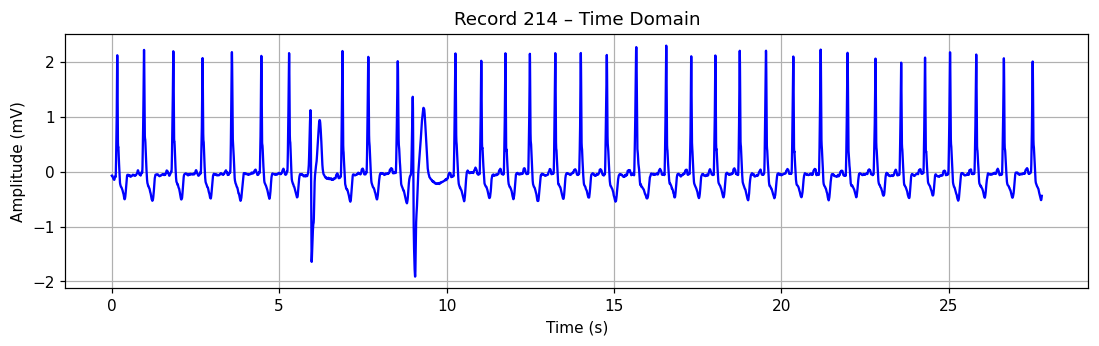

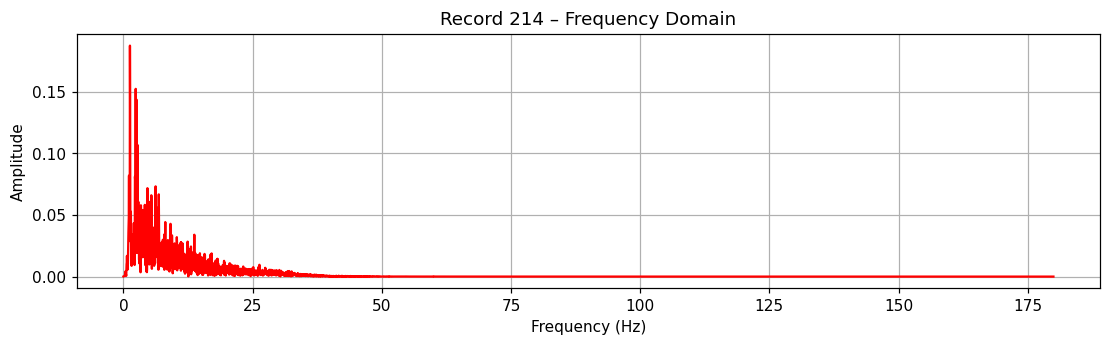

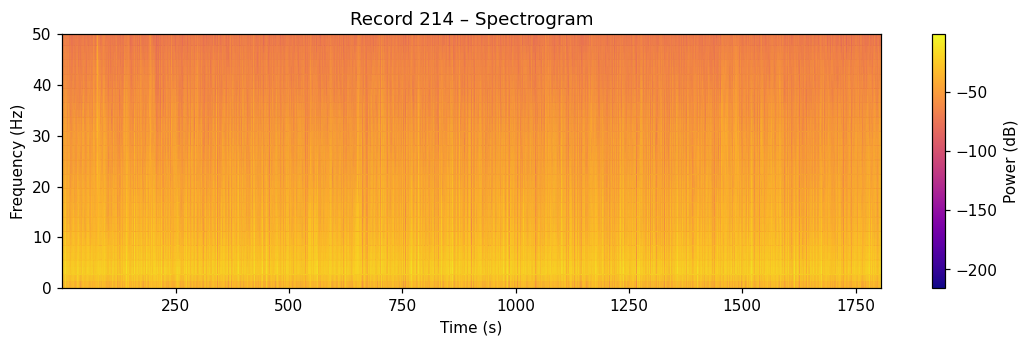

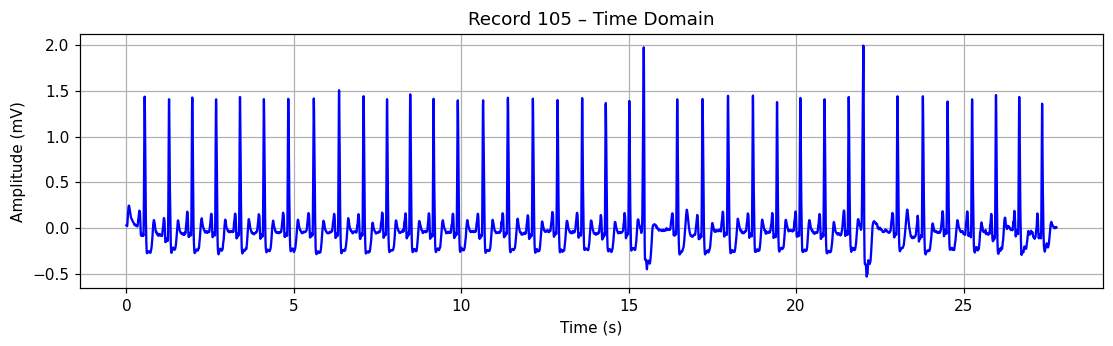

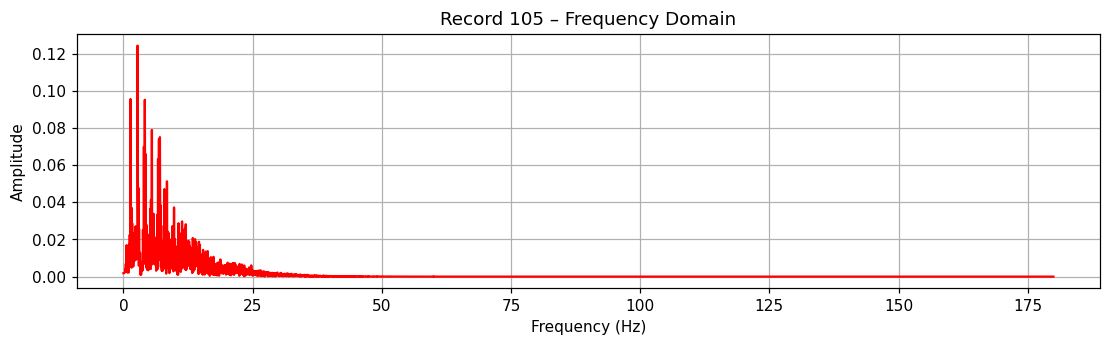

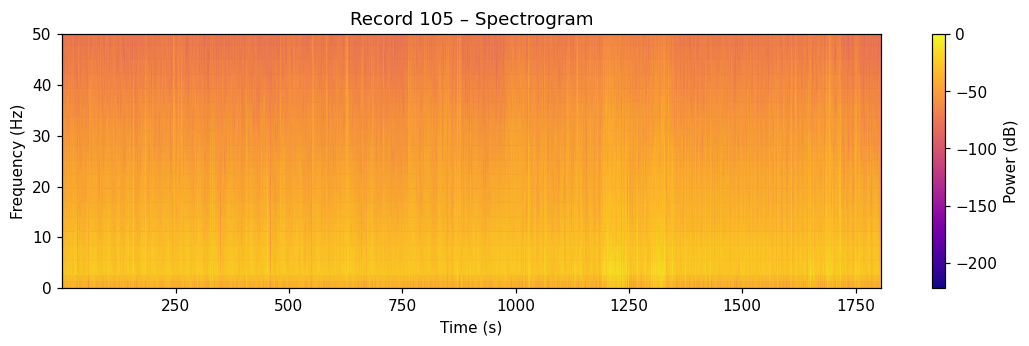

In [15]:
import wfdb

for rec_id in records_10:
    # Load record
    record = wfdb.rdrecord(rec_id, pn_dir='mitdb')
    ecg = record.p_signal[:,0]  # Lead II
    fs = record.fs
    
    # Band-pass filter
    ecg_bp = bandpass_filter(ecg, fs)
    
    # Plot all three representations
    plot_time_domain(ecg_bp, fs, rec_id)
    plot_frequency_domain(ecg_bp, fs, rec_id)
    plot_spectrogram(ecg_bp, fs, rec_id)


# *4. Feature Extraction and Comparison*

In [16]:
from scipy.signal import find_peaks

def detect_r_peaks(ecg, fs):
    # Find peaks: minimum distance ~0.25s (250 ms)
    distance = int(0.25 * fs)
    peaks, _ = find_peaks(ecg, distance=distance, height=np.mean(ecg)+0.5*np.std(ecg))
    return peaks


In [17]:
def compute_rr_and_hr(peaks, fs):
    rr_intervals = np.diff(peaks) / fs  # in seconds
    hr = 60 / rr_intervals               # in bpm
    return rr_intervals, hr


In [18]:
def hrv_time_domain(rr_intervals):
    mean_rr = np.mean(rr_intervals)
    sdnn = np.std(rr_intervals)
    rmssd = np.sqrt(np.mean(np.diff(rr_intervals)**2))
    return mean_rr, sdnn, rmssd


In [19]:
from scipy.signal import welch

def hrv_frequency_domain(rr_intervals):
    # Interpolate RR intervals to get evenly spaced signal
    rr_times = np.cumsum(rr_intervals)
    t_interp = np.linspace(rr_times[0], rr_times[-1], len(rr_intervals))
    rr_interp = np.interp(t_interp, rr_times, rr_intervals)  # fixed lengths
    
    # Compute PSD
    f, Pxx = welch(rr_interp, fs=4.0, nperseg=min(256, len(rr_interp)))  # 4 Hz interpolation
    
    # Power in different bands
    vlf = np.trapz(Pxx[(f>=0.0033) & (f<0.04)])
    lf  = np.trapz(Pxx[(f>=0.04) & (f<0.15)])
    hf  = np.trapz(Pxx[(f>=0.15) & (f<0.4)])
    
    return f, Pxx, vlf, lf, hf


In [20]:
# Band-pass filter ECG first (0.5–40 Hz)
ecg_bp = bandpass_filter(signal, fs)

# Detect R-peaks
r_peaks = detect_r_peaks(ecg_bp, fs)

# RR intervals and heart rate
rr_intervals, hr = compute_rr_and_hr(r_peaks, fs)

# Time-domain HRV
mean_rr, sdnn, rmssd = hrv_time_domain(rr_intervals)

# Frequency-domain HRV
f_psd, Pxx, vlf, lf, hf = hrv_frequency_domain(rr_intervals)

print(f"Record {rec_id} | HR mean: {np.mean(hr):.1f} bpm | SDNN: {sdnn:.3f} s | RMSSD: {rmssd:.3f} s")
print(f"VLF: {vlf:.3f}, LF: {lf:.3f}, HF: {hf:.3f}")


Record 105 | HR mean: 104.2 bpm | SDNN: 0.153 s | RMSSD: 0.168 s
VLF: 0.031, LF: 0.075, HF: 0.106


Selected records: ['222', '107', '101', '118', '116', '115', '108', '106', '214', '105']


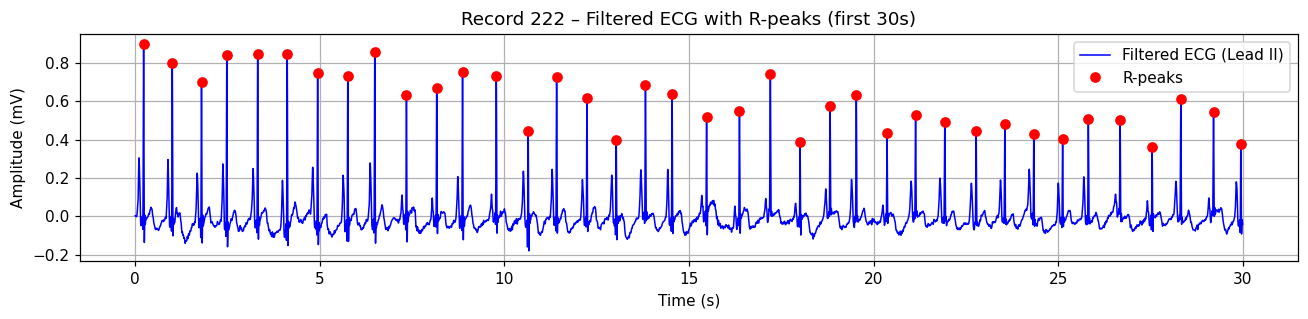

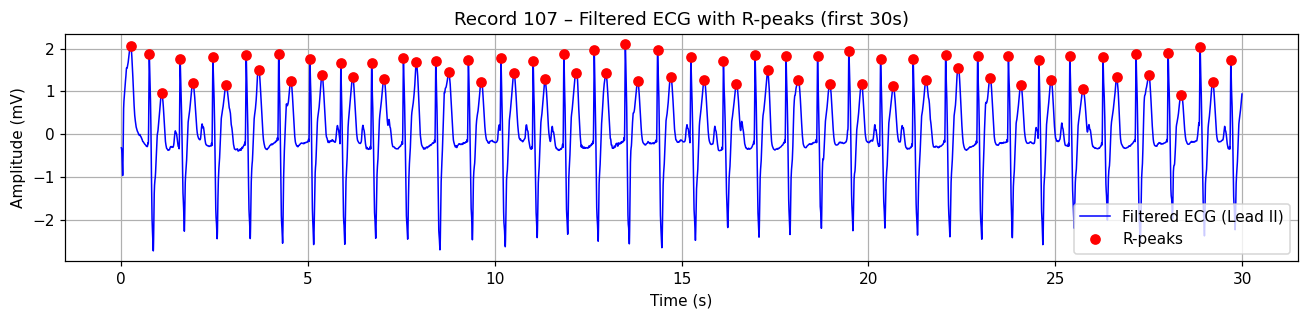

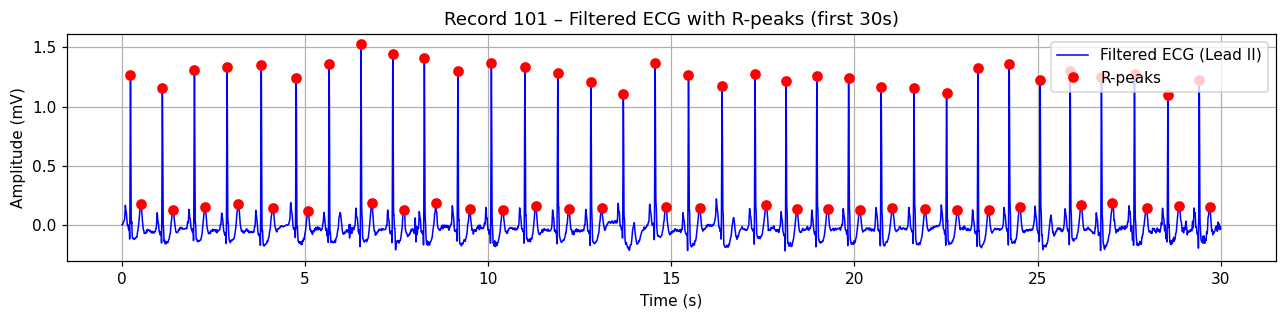

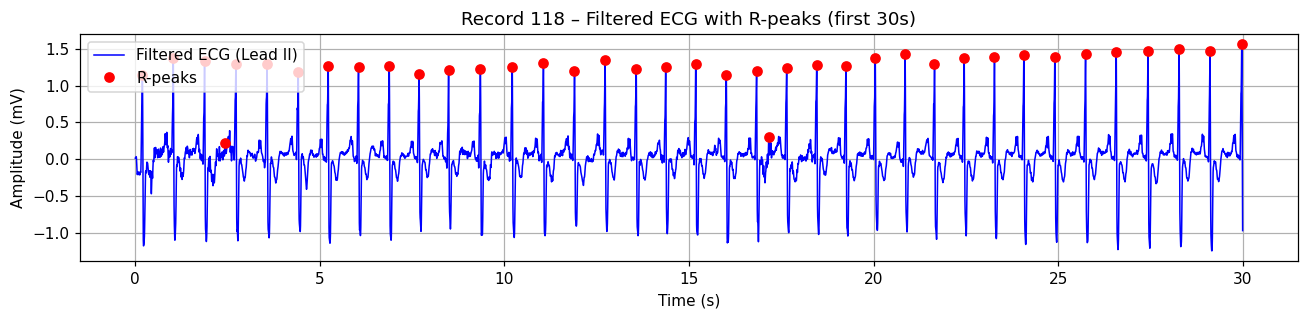

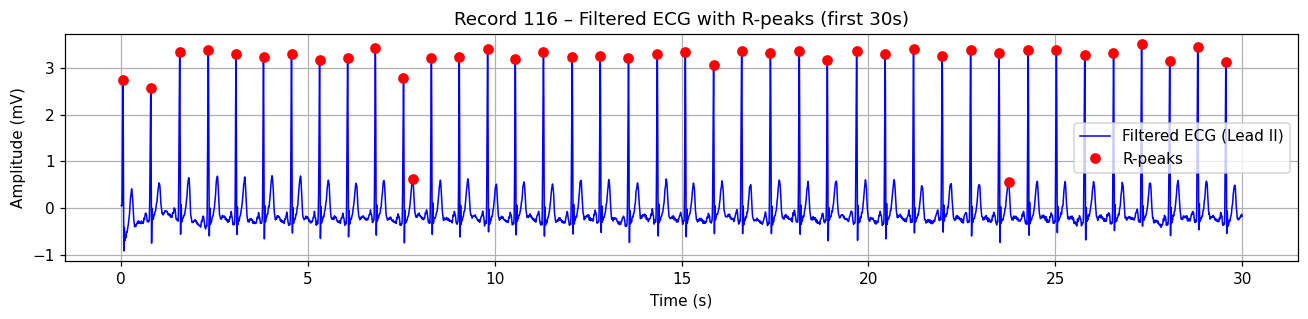

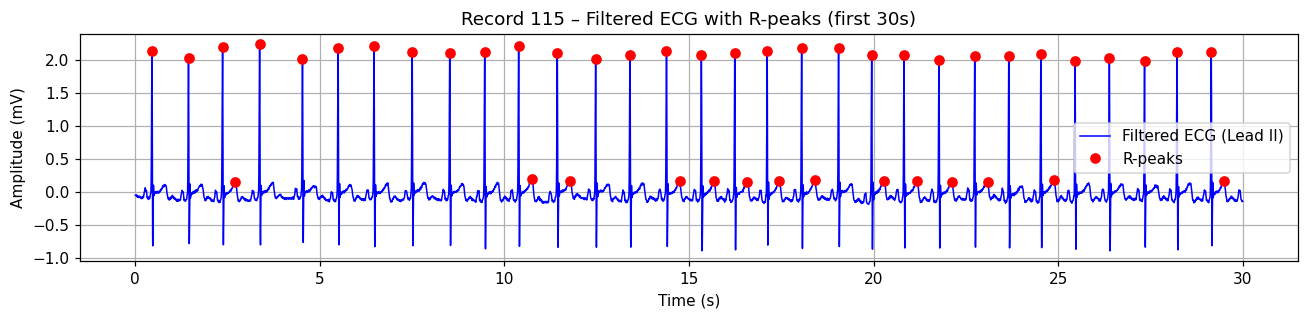

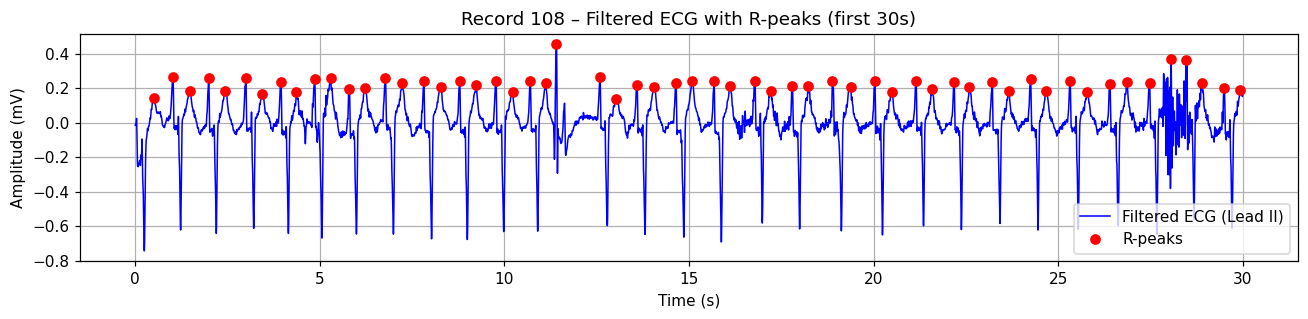

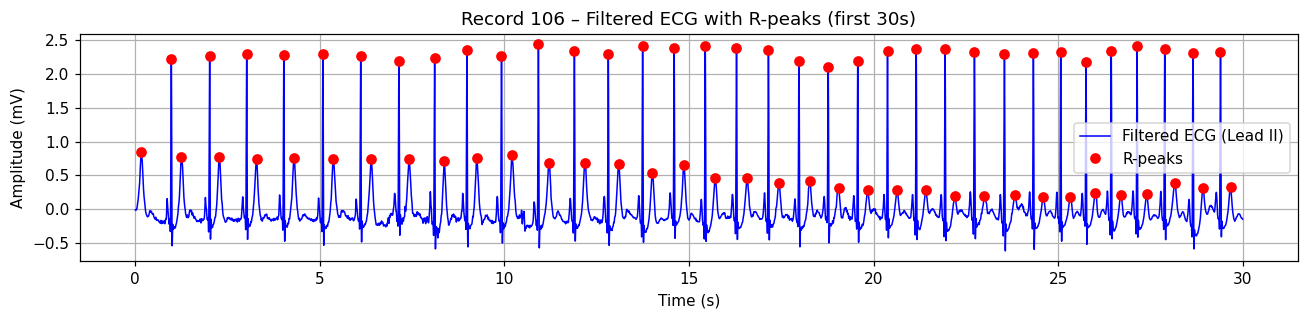

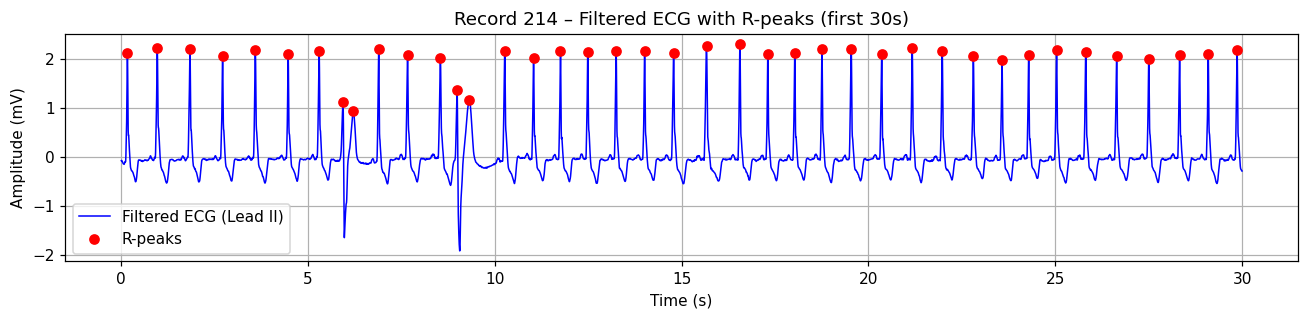

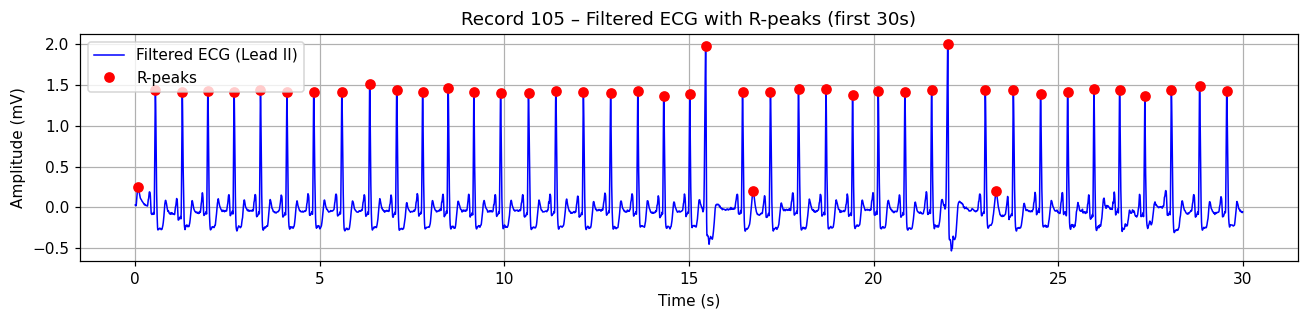

In [21]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, find_peaks, welch
import random
import pandas as pd

def bandpass_filter(sig, fs, lowcut=0.5, highcut=40.0, order=4):
    nyq = 0.5 * fs
    b, a = butter(order, [lowcut/nyq, highcut/nyq], btype='band')
    return filtfilt(b, a, sig)

def detect_r_peaks(ecg, fs):
    distance = int(0.25 * fs)  # min 250ms between peaks
    threshold = np.mean(ecg) + 0.5*np.std(ecg)
    peaks, _ = find_peaks(ecg, distance=distance, height=threshold)
    return peaks

def compute_rr_and_hr(peaks, fs):
    rr_intervals = np.diff(peaks) / fs
    hr = 60 / rr_intervals
    return rr_intervals, hr

def hrv_time_domain(rr_intervals):
    mean_rr = np.mean(rr_intervals)
    sdnn = np.std(rr_intervals)
    rmssd = np.sqrt(np.mean(np.diff(rr_intervals)**2))
    return mean_rr, sdnn, rmssd

def hrv_frequency_domain(rr_intervals):
    # Interpolation to evenly spaced signal
    rr_times = np.cumsum(rr_intervals)
    t_interp = np.linspace(rr_times[0], rr_times[-1], len(rr_intervals))
    rr_interp = np.interp(t_interp, rr_times, rr_intervals)
    
    # PSD
    f, Pxx = welch(rr_interp, fs=4.0, nperseg=min(256, len(rr_interp)))
    
    vlf = np.trapz(Pxx[(f>=0.0033) & (f<0.04)])
    lf  = np.trapz(Pxx[(f>=0.04) & (f<0.15)])
    hf  = np.trapz(Pxx[(f>=0.15) & (f<0.4)])
    
    return f, Pxx, vlf, lf, hf

#========================================================
all_records = [
    '100','101','102','103','104','105','106','107','108','109',
    '111','112','113','114','115','116','117','118','119','121',
    '122','123','124','200','201','202','203','205','207','208',
    '209','210','212','213','214','215','217','219','220','221',
    '222','223','228','230','231','232','233','234'
]

random.seed(42)
records_10 = random.sample(all_records, 10)
print("Selected records:", records_10)

#===========================================================
results = []

for rec_id in records_10:
    record = wfdb.rdrecord(rec_id, pn_dir='mitdb')
    signal = record.p_signal[:,0]  # Lead II
    fs = record.fs
    
    # Band-pass filter
    ecg_bp = bandpass_filter(signal, fs)
    
    # Detect R-peaks
    r_peaks = detect_r_peaks(ecg_bp, fs)
    
    # RR intervals and HR
    rr_intervals, hr = compute_rr_and_hr(r_peaks, fs)
    
    # Time-domain HRV
    mean_rr, sdnn, rmssd = hrv_time_domain(rr_intervals)
    
    # Frequency-domain HRV
    f_psd, Pxx, vlf, lf, hf = hrv_frequency_domain(rr_intervals)
    
    # Store results
    results.append({
        'Record': rec_id,
        'Mean HR (bpm)': np.mean(hr),
        'SDNN (s)': sdnn,
        'RMSSD (s)': rmssd,
        'VLF': vlf,
        'LF': lf,
        'HF': hf,
        'LF/HF': lf/hf if hf!=0 else np.nan,
        'Num Beats': len(r_peaks)
    })
    
    # Plot ECG with R-peaks (first 30s)
    plot_seconds = 30
    end_sample = int(plot_seconds * fs)
    t = np.arange(end_sample) / fs
    plt.figure(figsize=(12,3))
    plt.plot(t, ecg_bp[:end_sample], color='blue', lw=1, label='Filtered ECG (Lead II)')
    r_mask = r_peaks < end_sample
    plt.plot(r_peaks[r_mask]/fs, ecg_bp[r_peaks[r_mask]], 'ro', label='R-peaks')
    plt.title(f"Record {rec_id} – Filtered ECG with R-peaks (first {plot_seconds}s)")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude (mV)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [22]:
df_results = pd.DataFrame(results)
df_results

,Record,Mean HR (bpm),SDNN (s),RMSSD (s),VLF,LF,HF,LF/HF,Num Beats
0,222,104.055784,0.232439,0.256618,0.058155,0.370902,0.572368,0.648012,2721
1,107,146.538946,0.094232,0.179756,0.001983,0.005341,0.022414,0.238302,4210
2,101,139.898931,0.184159,0.348200,0.034830,0.085477,0.065693,1.301158,3649
3,118,102.000503,0.214793,0.200696,0.133562,0.136655,0.181841,0.751510,2643
4,116,94.365252,0.219877,0.311575,0.315877,2.044355,2.239221,0.912976,2574
5,115,128.490255,0.216707,0.285726,0.156433,0.351154,0.350503,1.001859,3355
6,108,104.592363,0.305910,0.298521,0.535857,0.547109,0.570662,0.958727,2547
7,106,143.238189,0.284026,0.475666,0.138595,0.151490,0.213132,0.710781,3371
8,214,91.524596,0.186309,0.227338,0.033411,0.110259,0.110500,0.997812,2468
9,105,104.190896,0.153404,0.168138,0.031492,0.075035,0.105764,0.709455,2848


In this last step, we analyzed ECG signals from 10 randomly selected MIT-BIH records to extract **heart rate (HR) and heart rate variability (HRV) metrics**, both in the **time domain** and **frequency domain**.

- **R-peak detection and RR intervals**  
  - R-peaks mark individual heartbeats, allowing computation of **RR intervals** (time between consecutive beats).  
  - These intervals are the foundation for time-domain and frequency-domain HRV analysis.

- **Time-domain HRV metrics**  
  - **Mean HR**: Average heart rate. Records above 100 bpm indicate fast rhythm or potential tachycardia.  
  - **SDNN** (standard deviation of RR intervals): Measures overall variability. High SDNN suggests irregular or arrhythmic rhythm.  
  - **RMSSD**: Measures short-term variability. Higher values indicate more beat-to-beat variation, often present in arrhythmias.

- **Frequency-domain HRV metrics**  
  - **VLF (0.0033–0.04 Hz), LF (0.04–0.15 Hz), HF (0.15–0.4 Hz)** reflect autonomic nervous system activity.  
  - **LF/HF ratio** shows balance between sympathetic and parasympathetic control.  
  - Irregular or fast rhythms often show altered LF/HF ratios.

- **Observations across 10 records**  
  - Records **116, 214, 105**: Moderate HR and SDNN/RMSSD → near-normal rhythm.  
  - Records **107, 101, 106, 115**: High HR, irregular SDNN/RMSSD → likely arrhythmic.  
  - Differences in RR interval variability and frequency-domain powers help distinguish **normal vs arrhythmic signals**.

### Conclusion

- **Feature extraction** allows quantification of heart rhythm and variability.  
- **Time-domain metrics** effectively highlight **irregular heartbeat patterns**, while **frequency-domain metrics** provide insight into autonomic regulation.  
- Comparing 10 random records, we can **identify potential arrhythmias** based on elevated HR, irregular RR intervals, high SDNN/RMSSD, or abnormal LF/HF ratios.  
- This demonstrates that **signal processing and HRV metrics** are powerful tools for detecting cardiac abnormalities in ECG signals.
